# EDA de los datos de la fuente del DGSIAP

### Pregunta de investigación: 
* Recordamos la pregunta de investigación para tener claro el enfoque durante este proceso:
**¿Qué relación tuvieron las variaciones de los precios regionales del maíz en México con los rendimientos mensuales de las acciones de Gruma en la Bolsa Mexicana de Valores entre 2013 y 2025?**

### 1. Cargamos los datos:

In [1]:
import pandas as pd
from rendimiento_bachoco.config import * #import DGSIAP_START_YEAR, DGSIAP_END_YEAR
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

2026-10-28 15:14:49.635 | INFO     | rendimiento_bachoco.config:<module>:15 - La ruta de PROJ_ROOT es: /Users/marcoramonet/Documents/MCD/IC/Rendimiento_Bursatil_Secondary_Worktree


Especificamos algunas configuraciones para poder visualizar los datos claramente.

In [2]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

Cargamos un archivo .csv por año, desde `DGSIAP_START_YEAR` hasta `DGSIAP_END_YEAR`, ambos incluidos. Con la configuración actual, el intervalo es 2013–2025: 13 años (`DGSIAP_END_YEAR - DGSIAP_START_YEAR + 1`). Como `range()` excluye su límite superior, usamos `DGSIAP_END_YEAR + 1`. Comprobamos que los años cargados coincidan exactamente con el intervalo configurado, sin años faltantes ni posteriores al año final.

In [3]:
dgsiap_df = pd.DataFrame()
for year in range(DGSIAP_START_YEAR, DGSIAP_END_YEAR + 1):
    maiz = pd.read_csv(INTERIM_DATA_DIR / 'DGSIAP'/ f'{year}.csv')
    dgsiap_df = pd.concat([dgsiap_df, maiz])

anios_esperados_dgsiap = list(range(DGSIAP_START_YEAR, DGSIAP_END_YEAR + 1))
assert sorted(dgsiap_df['Anio'].unique().tolist()) == anios_esperados_dgsiap, (
    'La cobertura temporal no coincide con el intervalo DGSIAP inclusivo configurado.'
)


### 2.1 Primer análisis:


In [4]:
dgsiap_df.head()

,Unnamed: 0,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,Nomcicloproductivo,Idmodalidad,Nommodalidad,Idunidadmedida,Nomunidad,Idcultivo,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,Nomcultivo Sin Um,Preciomediorural
0,1,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,5490000,Avena forrajera en verde,798.0,798.0,0.0,21181.0,26.54,603.77,1.278845e+07,NaN,NaN
1,9,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,1,Riego,200201,Tonelada,7470000,Maíz forrajero en verde,3187.0,3187.0,0.0,200503.0,62.91,615.49,1.234076e+08,NaN,NaN
2,10,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,1,Riego,200201,Tonelada,7490000,Maíz grano,230.0,230.0,0.0,1699.0,7.39,3576.02,6.075658e+06,NaN,NaN
3,13,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,2,Temporal,200201,Tonelada,5490000,Avena forrajera en verde,313.0,313.0,0.0,2497.0,7.98,470.28,1.174289e+06,NaN,NaN
4,15,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7470000,Maíz forrajero en verde,14477.0,14477.0,0.0,146777.0,10.14,516.43,7.580005e+07,NaN,NaN


In [5]:
dgsiap_df.shape

(100922, 27)

Obtenemos un primer vistazo sobre los datos:

In [6]:
dgsiap_df.columns.tolist()

['Unnamed: 0',
 'Anio',
 'Idestado',
 'Nomestado',
 'Idddr',
 'Nomddr',
 'Idcader',
 'Nomcader',
 'Idmunicipio',
 'Nommunicipio',
 'Idciclo',
 'Nomcicloproductivo',
 'Idmodalidad',
 'Nommodalidad',
 'Idunidadmedida',
 'Nomunidad',
 'Idcultivo',
 'Nomcultivo',
 'Sembrada',
 'Cosechada',
 'Siniestrada',
 'Volumenproduccion',
 'Rendimiento',
 'Precio',
 'Valorproduccion',
 'Nomcultivo Sin Um',
 'Preciomediorural']

In [7]:
dgsiap_df.info()

<class 'pandas.DataFrame'>
Index: 100922 entries, 0 to 7709
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Unnamed: 0          100922 non-null  int64  
 1   Anio                100922 non-null  int64  
 2   Idestado            100922 non-null  int64  
 3   Nomestado           100922 non-null  str    
 4   Idddr               100922 non-null  int64  
 5   Nomddr              100922 non-null  str    
 6   Idcader             100922 non-null  int64  
 7   Nomcader            100922 non-null  str    
 8   Idmunicipio         100922 non-null  int64  
 9   Nommunicipio        100922 non-null  str    
 10  Idciclo             100922 non-null  int64  
 11  Nomcicloproductivo  100922 non-null  str    
 12  Idmodalidad         100922 non-null  int64  
 13  Nommodalidad        100922 non-null  str    
 14  Idunidadmedida      100922 non-null  int64  
 15  Nomunidad           100922 non-null  str    
 16  Id

Observaciones: 
- Las columnas 'Nomcultivo' y 'Nomcultivo Sin Um' son el mismo atributo, pero hay una inconsistencia en el nombre de la variable por eso se observan los valores nulos.
- Es el mismo caso de 'precio' y 'Preciomediorural'.
- Además de las diferencias de nombres, `Rendimiento` contiene valores faltantes en 2024 y 2025; se revisan junto con los precios faltantes más adelante.

Analizamos que las inconsistencias embonen en cantidades de valores nulos:

In [8]:
dgsiap_df['Nomcultivo'].isnull().sum() + dgsiap_df['Nomcultivo Sin Um'].isnull().sum() == dgsiap_df.shape[0]

np.True_

In [9]:
dgsiap_df['Precio'].isnull().sum() + dgsiap_df['Preciomediorural'].isnull().sum() == dgsiap_df.shape[0]

np.False_

Podemos ver que nuestra suposición se verifica con 'Nomcultivo', pero no con 'Precio'. Sin embargo, podemos ver en los metadatos que 'Precio' se describe como 'Preciomediorural', por lo que podemos asumir que es la misma variable. Investigamos los valores faltantes que restan en la columna de 'Precio'. En el intervalo inclusivo 2013–2025, el cálculo siguiente identifica 64 entradas faltantes entre todos los cultivos cargados:

In [10]:
dgsiap_df[['Precio', 'Preciomediorural']].isnull().sum().agg('sum') - dgsiap_df.shape[0]

np.int64(64)

Tomamos el primer subconjunto de los datos, en particular los datos que contienen el cultivo de interés, el maíz:

In [11]:
maiz = dgsiap_df.loc[(dgsiap_df['Nomcultivo'] == 'Maíz grano') | (dgsiap_df['Nomcultivo Sin Um'] == 'Maíz grano')]
maiz = maiz.drop(columns = 'Unnamed: 0') # Remanente del index en la fuente de datos raw

Reemplazamos las entradas faltantes de 'Precio' con las entradas de 'Preciomediorural':

In [12]:
maiz['Precio'] = maiz['Precio'].fillna(maiz['Preciomediorural'])
maiz = maiz.drop(columns = 'Preciomediorural')

Hacemos lo mismo con 'Nomcultivo':

In [13]:
maiz['Nomcultivo'] = maiz['Nomcultivo'].fillna(maiz['Nomcultivo Sin Um'])
maiz = maiz.drop(columns = 'Nomcultivo Sin Um')

In [14]:
maiz.isna().sum()

Anio                   0
Idestado               0
Nomestado              0
Idddr                  0
Nomddr                 0
Idcader                0
Nomcader               0
Idmunicipio            0
Nommunicipio           0
Idciclo                0
Nomcicloproductivo     0
Idmodalidad            0
Nommodalidad           0
Idunidadmedida         0
Nomunidad              0
Idcultivo              0
Nomcultivo             0
Sembrada               0
Cosechada              0
Siniestrada            0
Volumenproduccion      0
Rendimiento           29
Precio                29
Valorproduccion        0
dtype: int64

Y descubrimos los verdaderos valores faltantes

In [15]:
maiz.loc[(maiz['Rendimiento'].isnull()) | (maiz['Precio'].isnull())]

,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,Nomcicloproductivo,Idmodalidad,Nommodalidad,Idunidadmedida,Nomunidad,Idcultivo,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion
283,2024,5,Coahuila,192,Laguna-Coahuila,11,Torreón,35,Torreón,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,19.00,0.0,19.00,0.0,NaN,NaN,0.0
582,2024,8,Chihuahua,28,Casas Grandes,1,Nuevo Casas Grandes,13,Casas Grandes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
588,2024,8,Chihuahua,28,Casas Grandes,1,Nuevo Casas Grandes,50,Nuevo Casas Grandes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,50.00,0.0,50.00,0.0,NaN,NaN,0.0
596,2024,8,Chihuahua,28,Casas Grandes,2,Janos,35,Janos,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
1137,2024,10,Durango,191,Laguna-Durango,4,Sn. Pedro El Gallo,30,San Pedro del Gallo,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,705.00,0.0,705.00,0.0,NaN,NaN,0.0
1167,2024,10,Durango,191,Laguna-Durango,16,Rodeo,24,Rodeo,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,725.50,0.0,725.50,0.0,NaN,NaN,0.0
1176,2024,10,Durango,191,Laguna-Durango,18,Bermejillo,13,Mapimí,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,40.00,0.0,40.00,0.0,NaN,NaN,0.0
6075,2024,24,San Luis Potosí,129,Rioverde,1,Cárdenas,2,Alaquines,1,Otoño-Invierno,2,Temporal,200201,Tonelada,7490000,Maíz grano,25.00,0.0,25.00,0.0,NaN,NaN,0.0
6186,2024,25,Sinaloa,133,Los Mochis,2,El Fuerte,10,El Fuerte,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
6447,2024,26,Sonora,148,Cajeme,6,Rosario,49,Quiriego,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,25.00,0.0,25.00,0.0,NaN,NaN,0.0


En el maíz, los 29 registros con rendimiento o precio faltante corresponden a 19 casos de 2024 y 10 de 2025. En todos ellos, la superficie 'Siniestrada' es igual a la 'Sembrada' y la 'Cosechada' es 0.0. Conservamos el tratamiento existente de reemplazar esos faltantes con ceros para procesarlos junto con el resto del conjunto. Un precio cero sin producción no representa una transacción observada a precio cero; la sección 3 compara su efecto sobre las medias.

In [16]:
maiz['Rendimiento'] = maiz['Rendimiento'].fillna(0.0) 
maiz['Precio'] = maiz['Precio'].fillna(0.0) 
maiz.isna().sum()

Anio                  0
Idestado              0
Nomestado             0
Idddr                 0
Nomddr                0
Idcader               0
Nomcader              0
Idmunicipio           0
Nommunicipio          0
Idciclo               0
Nomcicloproductivo    0
Idmodalidad           0
Nommodalidad          0
Idunidadmedida        0
Nomunidad             0
Idcultivo             0
Nomcultivo            0
Sembrada              0
Cosechada             0
Siniestrada           0
Volumenproduccion     0
Rendimiento           0
Precio                0
Valorproduccion       0
dtype: int64

Buscamos anomalías basándonos en la última observación, tomando en cuenta que el volumen de 'Sembrada' debe ser igual a 'Siniestra' más 'Cosechada': 

In [17]:
maiz['VolumenCosechaCalculado'] = maiz['Cosechada'] + maiz['Siniestrada']
maiz['VolumenCosechaCalculado'] = (maiz['Cosechada'] + maiz['Siniestrada']).round(decimals=2)
len(maiz[maiz['VolumenCosechaCalculado'] > maiz['Sembrada']])

0

Buscamos anomalías haciendo una observación similar, pero en el caso del rendimiento y observamos que no hay anomalías en este caso:

In [18]:
mask_cosechada = maiz['Cosechada'] > 0 # Evitar división por cero
maiz['RendimientoCalculado'] = np.where(mask_cosechada, maiz['Volumenproduccion'] / maiz['Sembrada'], 0).round(decimals = 2)
err_inf = maiz['RendimientoCalculado'] - 0.01
err_sup = maiz['RendimientoCalculado'] + 0.01
len(maiz.loc[(maiz['Rendimiento'] < err_inf) & (maiz['Rendimiento'] > err_sup)])

0

In [19]:
maiz.columns.tolist()

['Anio',
 'Idestado',
 'Nomestado',
 'Idddr',
 'Nomddr',
 'Idcader',
 'Nomcader',
 'Idmunicipio',
 'Nommunicipio',
 'Idciclo',
 'Nomcicloproductivo',
 'Idmodalidad',
 'Nommodalidad',
 'Idunidadmedida',
 'Nomunidad',
 'Idcultivo',
 'Nomcultivo',
 'Sembrada',
 'Cosechada',
 'Siniestrada',
 'Volumenproduccion',
 'Rendimiento',
 'Precio',
 'Valorproduccion',
 'VolumenCosechaCalculado',
 'RendimientoCalculado']

Ahora sabemos que, aunque hayan valores con 0.0, esto no implica que sean valores faltantes si no que indican una cosecha fallida. Al momento de hace un análisis, habrá que tratar estos valores de manera específica para que no afecten las estadísticas descriptivas como valores outlier, cuando en realidad indican algo=una situación en particular.

### 3 Análisis Descriptivo Uni-Variable

Tomamos un primer vistazo a las estadísticas:

In [20]:
maiz.describe()

,Anio,Idestado,Idddr,Idcader,Idmunicipio,Idciclo,Idmodalidad,Idunidadmedida,Idcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,VolumenCosechaCalculado,RendimientoCalculado
count,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.0,59856.0,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,5.985600e+04,59856.000000,59856.000000
mean,2019.002539,19.275511,103.585739,2.550605,114.266239,1.725658,1.612236,200201.0,7490000.0,1576.824696,1516.409593,60.415102,5660.538913,2.945679,4414.997069,2.534757e+07,1576.824696,2.903094
std,3.736742,7.138717,45.719123,1.766972,138.321981,0.446186,0.487244,0.0,0.0,3088.931910,3017.985451,430.953289,20548.859462,2.345819,1210.244261,9.531135e+07,3088.931910,2.350178
min,2013.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,200201.0,7490000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2016.000000,14.000000,71.000000,1.000000,22.000000,1.000000,1.000000,200201.0,7490000.0,78.400000,73.000000,0.000000,155.800000,1.220000,3640.000000,6.533597e+05,78.400000,1.200000
50%,2019.000000,20.000000,105.000000,2.000000,58.000000,2.000000,2.000000,200201.0,7490000.0,415.000000,392.000000,0.000000,740.000000,2.380000,4149.615000,3.147492e+06,415.000000,2.340000
75%,2022.000000,24.000000,128.000000,3.000000,144.000000,2.000000,2.000000,200201.0,7490000.0,1678.000000,1580.000000,0.000000,3348.120000,3.800000,4937.587500,1.440844e+07,1678.000000,3.780000
max,2025.000000,32.000000,193.000000,18.000000,570.000000,2.000000,2.000000,200201.0,7490000.0,39742.000000,39742.000000,29598.660000,500812.000000,15.300000,16500.000000,2.601964e+09,39742.000000,15.300000


In [21]:
maiz.describe(include = ['object', 'str'])

,Nomestado,Nomddr,Nomcader,Nommunicipio,Nomcicloproductivo,Nommodalidad,Nomunidad,Nomcultivo
count,59856,59856,59856,59856,59856,59856,59856,59856
unique,33,188,665,2286,2,2,1,1
top,Oaxaca,Valles Centrales,Etla,Sinaloa,Primavera-Verano,Temporal,Tonelada,Maíz grano
freq,15394,5274,2911,156,43435,36646,59856,59856


#### 3.1 Alcance, cobertura y unidad de observación

Estudiamos `Rendimiento` (toneladas/hectárea), `Precio` (pesos/tonelada), `Valorproduccion` (pesos corrientes) y `Volumenproduccion` (toneladas). Los registros originales distinguen año, ubicación, ciclo agrícola y modalidad hídrica; no representan observaciones independientes de un experimento.

Trabajamos sobre una **copia de `maiz`**, sin modificar su preparación previa. Unificamos `Ciudad de México / DF` y `Ciudad de México`, que comparten `Idestado = 9`, para no dividir artificialmente su historia. El periodo se obtiene de los datos efectivamente cargados y debe coincidir con el intervalo configurado, incluidos ambos extremos: 2013–2025 (13 años) con la configuración actual. La carga usa `DGSIAP_END_YEAR + 1` para incluir el año final.

Conservamos los ceros y los extremos. Un volumen cero no se elimina como dato atípico; revisamos su relación con la superficie cosechada y siniestrada. En particular, un precio cero sin producción no equivale a una transacción realizada a precio cero.

In [22]:
# Reutilizamos las bibliotecas importadas y añadimos utilidades de presentación.
from IPython.display import Markdown, display
from matplotlib.colors import Normalize

variables_univariables = ['Rendimiento', 'Precio', 'Valorproduccion', 'Volumenproduccion']
claves_univariables = ['Nomestado', 'Anio']
auxiliares_univariables = ['Idestado', 'Sembrada', 'Cosechada', 'Siniestrada']
maiz_univariable = maiz[claves_univariables + auxiliares_univariables + variables_univariables].copy()

# Mostramos la equivalencia geográfica antes de normalizarla exclusivamente en la copia.
equivalencias_cdmx = maiz_univariable.loc[
    maiz_univariable['Idestado'].eq(9), ['Idestado', 'Nomestado']
].drop_duplicates().reset_index(drop=True)
display(equivalencias_cdmx)
maiz_univariable['Nomestado'] = maiz_univariable['Nomestado'].replace(
    {'Ciudad de México / DF': 'Ciudad de México'}
)
anios_univariables = sorted(maiz_univariable['Anio'].unique())
periodo_univariable = f'{anios_univariables[0]}–{anios_univariables[-1]}'
sin_produccion = maiz_univariable['Volumenproduccion'].eq(0)

# El diagnóstico distingue ausencia, cero y valores negativos sin corregirlos silenciosamente.
diagnostico_univariable = pd.DataFrame({
    'Registros válidos': maiz_univariable[variables_univariables].count(),
    'Faltantes': maiz_univariable[variables_univariables].isna().sum(),
    'Ceros': maiz_univariable[variables_univariables].eq(0).sum(),
    'Negativos': maiz_univariable[variables_univariables].lt(0).sum(),
}).rename_axis('Variable').reset_index()
display(Markdown(
    f'**Cobertura:** {len(maiz_univariable):,} registros; '
    f'{maiz_univariable.Nomestado.nunique()} estados; periodo {periodo_univariable}.'
))
display(diagnostico_univariable)
display(pd.DataFrame({
    'Condición': ['Sin producción', 'Sin producción y sin superficie cosechada',
                 'Sin producción y superficie sembrada igual a siniestrada',
                 'Precio cero con producción positiva'],
    'Registros': [sin_produccion.sum(),
                  (sin_produccion & maiz_univariable.Cosechada.eq(0)).sum(),
                  (sin_produccion & np.isclose(maiz_univariable.Sembrada,
                                               maiz_univariable.Siniestrada, rtol=0, atol=0.01)).sum(),
                  (maiz_univariable.Precio.eq(0) & maiz_univariable.Volumenproduccion.gt(0)).sum()],
}))

,Idestado,Nomestado
0,9,Ciudad de México / DF
1,9,Ciudad de México


**Cobertura:** 59,856 registros; 32 estados; periodo 2013–2025.

,Variable,Registros válidos,Faltantes,Ceros,Negativos
0,Rendimiento,59856,0,292,0
1,Precio,59856,0,292,0
2,Valorproduccion,59856,0,292,0
3,Volumenproduccion,59856,0,292,0


,Condición,Registros
0,Sin producción,292
1,Sin producción y sin superficie cosechada,292
2,Sin producción y superficie sembrada igual a siniestrada,292
3,Precio cero con producción positiva,0


#### 3.2 Agregación por estado y año

Creamos **cuatro dataframes independientes**, con una fila por combinación `Nomestado`–`Anio` y un índice simple mediante `.reset_index()`. Conservar el año permite construir las series temporales sin asignar un año arbitrario a un resumen de todo el periodo.

- `rendimiento_estado_anio`: **media simple** del rendimiento de los registros; no es el cociente entre producción total y superficie cosechada total.
- `precio_estado_anio`: **media simple** del precio; no está ponderada por toneladas producidas.
- `valorproduccion_estado_anio`: **valor medio por registro**, no valor total estatal.
- `volumenproduccion_estado_anio`: **suma de la producción anual estatal**.

Todos incluyen los registros sin producción. La tabla de cobertura permite revisar cuántos registros contribuyen a cada agregado: las medias simples pueden cambiar cuando cambia la composición de los registros.

In [23]:
# Agrupamos siempre por las mismas claves; sort=True mantiene un orden reproducible.
rendimiento_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Rendimiento']
    .agg('mean').reset_index()
)
precio_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Precio']
    .agg('mean').reset_index()
)
valorproduccion_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Valorproduccion']
    .agg('mean').reset_index()
)
volumenproduccion_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Volumenproduccion']
    .agg('sum', min_count=1).reset_index()
)
agregados_univariables = {
    'Rendimiento': rendimiento_estado_anio,
    'Precio': precio_estado_anio,
    'Valorproduccion': valorproduccion_estado_anio,
    'Volumenproduccion': volumenproduccion_estado_anio,
}

# Conservamos conteos por estado/año y una matriz compacta que expone posibles huecos.
cobertura_estado_anio = (
    maiz_univariable.assign(SinProduccion=sin_produccion)
    .groupby(claves_univariables, sort=True)
    .agg(Registros=('Volumenproduccion', 'size'), SinProduccion=('SinProduccion', 'sum'))
    .reset_index()
)
for variable, tabla in agregados_univariables.items():
    display(Markdown(f'**{variable}:** {len(tabla)} combinaciones estado/año; primeras cinco filas.'))
    display(tabla.head().round(3))
display(Markdown('**Número de registros por estado y año** (un hueco significaría falta de cobertura):'))
with pd.option_context('display.max_rows', 40, 'display.max_columns', 15):
    display(cobertura_estado_anio.pivot(index='Nomestado', columns='Anio', values='Registros'))

**Rendimiento:** 416 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Rendimiento
0,Aguascalientes,2013,3.965
1,Aguascalientes,2014,3.962
2,Aguascalientes,2015,4.067
3,Aguascalientes,2016,3.790
4,Aguascalientes,2017,4.065


**Precio:** 416 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Precio
0,Aguascalientes,2013,3300.418
1,Aguascalientes,2014,3006.114
2,Aguascalientes,2015,3260.577
3,Aguascalientes,2016,3462.497
4,Aguascalientes,2017,3439.731


**Valorproduccion:** 416 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Valorproduccion
0,Aguascalientes,2013,1.161208e+07
1,Aguascalientes,2014,9.194384e+06
2,Aguascalientes,2015,9.242663e+06
3,Aguascalientes,2016,1.119376e+07
4,Aguascalientes,2017,1.279807e+07


**Volumenproduccion:** 416 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Volumenproduccion
0,Aguascalientes,2013,79955.60
1,Aguascalientes,2014,64271.21
2,Aguascalientes,2015,60309.42
3,Aguascalientes,2016,63384.75
4,Aguascalientes,2017,76937.09


**Número de registros por estado y año** (un hueco significaría falta de cobertura):

Anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Nomestado,,,,,,,,,,,,,
Aguascalientes,22,22,22,21,22,22,22,22,22,22,22,22,22
Baja California,6,5,7,8,13,6,6,8,9,10,11,4,6
Baja California Sur,9,10,10,8,9,10,9,8,10,10,10,10,10
Campeche,33,34,35,36,35,36,37,36,38,40,41,41,40
Chiapas,221,222,224,221,221,224,222,221,227,232,232,232,232
Chihuahua,74,74,78,76,73,74,77,78,82,81,81,75,76
Ciudad de México,7,7,7,7,7,7,7,7,7,7,7,7,7
Coahuila,54,57,63,55,52,54,47,43,46,48,49,54,51
Colima,26,26,26,27,25,22,26,26,26,26,27,27,27


#### 3.3 Distribución de registros frente a distribución de agregados

Los dos resúmenes siguientes responden preguntas distintas. El primero describe los **registros originales**, por lo que los estados con más registros tienen más peso. El segundo describe los **agregados estado/año**, dando el mismo peso a cada combinación observada. En volumen, el segundo resumen describe totales anuales estatales, no tamaños de registros.

Además de media, desviación estándar y extremos, calculamos cuartiles, mediana, rango intercuartílico (RIC) y asimetría. Una asimetría positiva señala una cola hacia valores altos; una diferencia importante entre media y mediana ayuda a reconocerla. Son estadísticas descriptivas, no pruebas de normalidad ni intervalos de confianza.

In [24]:
# Esta función presenta las mismas medidas en ambos niveles, sin mezclar sus unidades.
def resumir_univariables(datos):
    resumen = datos.describe().T.rename(columns={
        'count': 'N', 'mean': 'Media', 'std': 'Desv. estándar', 'min': 'Mínimo',
        '25%': 'Q1', '50%': 'Mediana', '75%': 'Q3', 'max': 'Máximo',
    })
    resumen['RIC'] = resumen['Q3'] - resumen['Q1']
    resumen['Asimetría'] = datos.skew()
    return resumen.rename_axis('Variable').reset_index()

# Alineamos por claves, nunca por la posición de las filas de diferentes tablas.
resumen_registros_univariable = resumir_univariables(maiz_univariable[variables_univariables])
valores_estado_anio = pd.concat(
    [tabla.set_index(claves_univariables)[variable]
     for variable, tabla in agregados_univariables.items()], axis=1
)
resumen_agregados_univariable = resumir_univariables(valores_estado_anio)
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(Markdown('**Nivel de registro original:**'))
    display(resumen_registros_univariable)
    display(Markdown('**Nivel estado/año (medias de las primeras tres variables y suma de volumen):**'))
    display(resumen_agregados_univariable)

**Nivel de registro original:**

,Variable,N,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría
0,Rendimiento,"59,856.000",2.946,2.346,0.000,1.220,2.380,3.800,15.300,2.580,1.638
1,Precio,"59,856.000","4,414.997","1,210.244",0.000,"3,640.000","4,149.615","4,937.587","16,500.000","1,297.587",0.753
2,Valorproduccion,"59,856.000","25,347,566.804","95,311,345.224",0.000,"653,359.745","3,147,492.165","14,408,438.562","2,601,963,631.000","13,755,078.818",11.449
3,Volumenproduccion,"59,856.000","5,660.539","20,548.859",0.000,155.800,740.000,"3,348.120","500,812.000","3,192.320",10.415


**Nivel estado/año (medias de las primeras tres variables y suma de volumen):**

,Variable,N,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría
0,Rendimiento,416.000,3.589,1.882,1.084,2.086,3.186,4.531,11.498,2.445,1.336
1,Precio,416.000,"4,442.306","1,116.986","1,520.000","3,598.530","4,091.795","5,156.339","7,571.545","1,557.809",0.845
2,Valorproduccion,416.000,"31,667,816.545","51,639,961.369","824,980.000","8,117,117.923","15,546,753.955","32,041,585.766","427,279,923.656","23,924,467.842",4.417
3,Volumenproduccion,416.000,"814,464.464","1,152,197.386","1,085.500","83,823.675","348,490.660","1,259,626.353","6,656,330.770","1,175,802.677",2.628


#### 3.4 Sensibilidad del rendimiento y del precio a los registros sin producción

La comparación **no reemplaza** los cuatro agregados principales. Calculamos nuevamente las medias de rendimiento y precio usando únicamente `Volumenproduccion > 0`, y las contrastamos con las medias que incluyen todos los registros.

La diferencia se define como **media con producción positiva menos media de todos los registros**. Ambas columnas siguen siendo medias simples. Una unión izquierda conserva incluso los grupos sin producción positiva: en esos casos, la media condicionada permanece ausente (`NaN`), porque no existe una observación que permita calcularla. La síntesis de diferencias da el mismo peso a cada estado/año con comparación disponible.

In [25]:
# Filtramos solo para la comparación; maiz_univariable y los agregados principales no cambian.
medias_con_produccion = (
    maiz_univariable.loc[maiz_univariable.Volumenproduccion.gt(0)]
    .groupby(claves_univariables)[['Rendimiento', 'Precio']].agg('mean').reset_index()
    .rename(columns={'Rendimiento': 'Rendimiento_positivo', 'Precio': 'Precio_positivo'})
)
comparacion_ceros_estado_anio = (
    cobertura_estado_anio
    .merge(rendimiento_estado_anio, on=claves_univariables, how='left', validate='one_to_one')
    .merge(precio_estado_anio, on=claves_univariables, how='left', validate='one_to_one')
    .merge(medias_con_produccion, on=claves_univariables, how='left', validate='one_to_one')
)
comparacion_ceros_estado_anio['Porcentaje_sin_produccion'] = (
    100 * comparacion_ceros_estado_anio.SinProduccion / comparacion_ceros_estado_anio.Registros
)
for variable in ['Rendimiento', 'Precio']:
    comparacion_ceros_estado_anio[f'Diferencia_{variable}'] = (
        comparacion_ceros_estado_anio[f'{variable}_positivo']
        - comparacion_ceros_estado_anio[variable]
    )
    # Mostramos ambos promedios junto con las diez mayores diferencias de cada variable.
    display(Markdown(f'**{variable}: diez mayores diferencias por estado/año**'))
    columnas_comparacion = claves_univariables + [
        'Registros', 'SinProduccion', variable, f'{variable}_positivo', f'Diferencia_{variable}'
    ]
    display(comparacion_ceros_estado_anio.nlargest(10, f'Diferencia_{variable}')
            [columnas_comparacion].round(3))

display(Markdown('**Síntesis de las diferencias entre medias por estado/año:**'))
display(comparacion_ceros_estado_anio[['Diferencia_Rendimiento', 'Diferencia_Precio']]
        .describe().round(3))
display(Markdown(
    f'Grupos con registros sin producción: '
    f'**{comparacion_ceros_estado_anio.SinProduccion.gt(0).sum()}**; '
    f'grupos sin registros de producción positiva: '
    f'**{comparacion_ceros_estado_anio.Precio_positivo.isna().sum()}**.'
))

**Rendimiento: diez mayores diferencias por estado/año**

,Nomestado,Anio,Registros,SinProduccion,Rendimiento,Rendimiento_positivo,Diferencia_Rendimiento
14,Baja California,2014,5,3,3.324,8.310,4.986
15,Baja California,2015,7,1,7.440,8.680,1.240
332,Sonora,2020,72,10,5.620,6.526,0.906
16,Baja California,2016,8,1,6.302,7.203,0.900
17,Baja California,2017,13,1,7.299,7.908,0.608
67,Chihuahua,2015,78,9,4.538,5.130,0.592
75,Chihuahua,2023,81,11,3.710,4.294,0.583
127,Durango,2023,72,12,2.870,3.444,0.574
285,Querétaro,2025,39,5,3.372,3.868,0.496
413,Zacatecas,2023,99,7,4.623,4.974,0.352


**Precio: diez mayores diferencias por estado/año**

,Nomestado,Anio,Registros,SinProduccion,Precio,Precio_positivo,Diferencia_Precio
14,Baja California,2014,5,3,1520.000,3800.000,2280.000
127,Durango,2023,72,12,5522.267,6626.720,1104.453
75,Chihuahua,2023,81,11,5712.882,6610.621,897.739
285,Querétaro,2025,39,5,4544.928,5213.299,668.372
240,Nuevo León,2019,69,11,3467.421,4125.036,657.614
332,Sonora,2020,72,10,3954.940,4592.833,637.894
246,Nuevo León,2025,36,4,5034.973,5664.345,629.372
362,Tamaulipas,2024,69,8,4680.114,5293.900,613.785
15,Baja California,2015,7,1,3375.744,3938.368,562.624
413,Zacatecas,2023,99,7,6673.740,7181.524,507.785


**Síntesis de las diferencias entre medias por estado/año:**

,Diferencia_Rendimiento,Diferencia_Precio
count,416.000,416.000
mean,0.044,44.880
std,0.270,164.715
min,0.000,0.000
25%,0.000,0.000
50%,0.000,0.000
75%,0.000,0.000
max,4.986,2280.000


Grupos con registros sin producción: **85**; grupos sin registros de producción positiva: **0**.

#### 3.5 Histogramas de los agregados estado/año

Cada histograma cuenta **combinaciones estado/año**, no registros originales. Los colores identifican la variable: verde para rendimiento, azul para precio, violeta para valor medio y naranja para volumen total. La línea negra discontinua indica la media y la roja punteada, la mediana.

Primero mostramos las cuatro distribuciones completas en escala lineal y con ejes independientes. Para volumen y valor, añadimos una vista con intervalos logarítmicos cuando todos los agregados son positivos: facilita examinar órdenes de magnitud sin eliminar extremos. Si aparecen ceros, esa vista conserva la escala lineal. La frecuencia es el número de observaciones en cada intervalo, no una densidad comparable entre escalas.

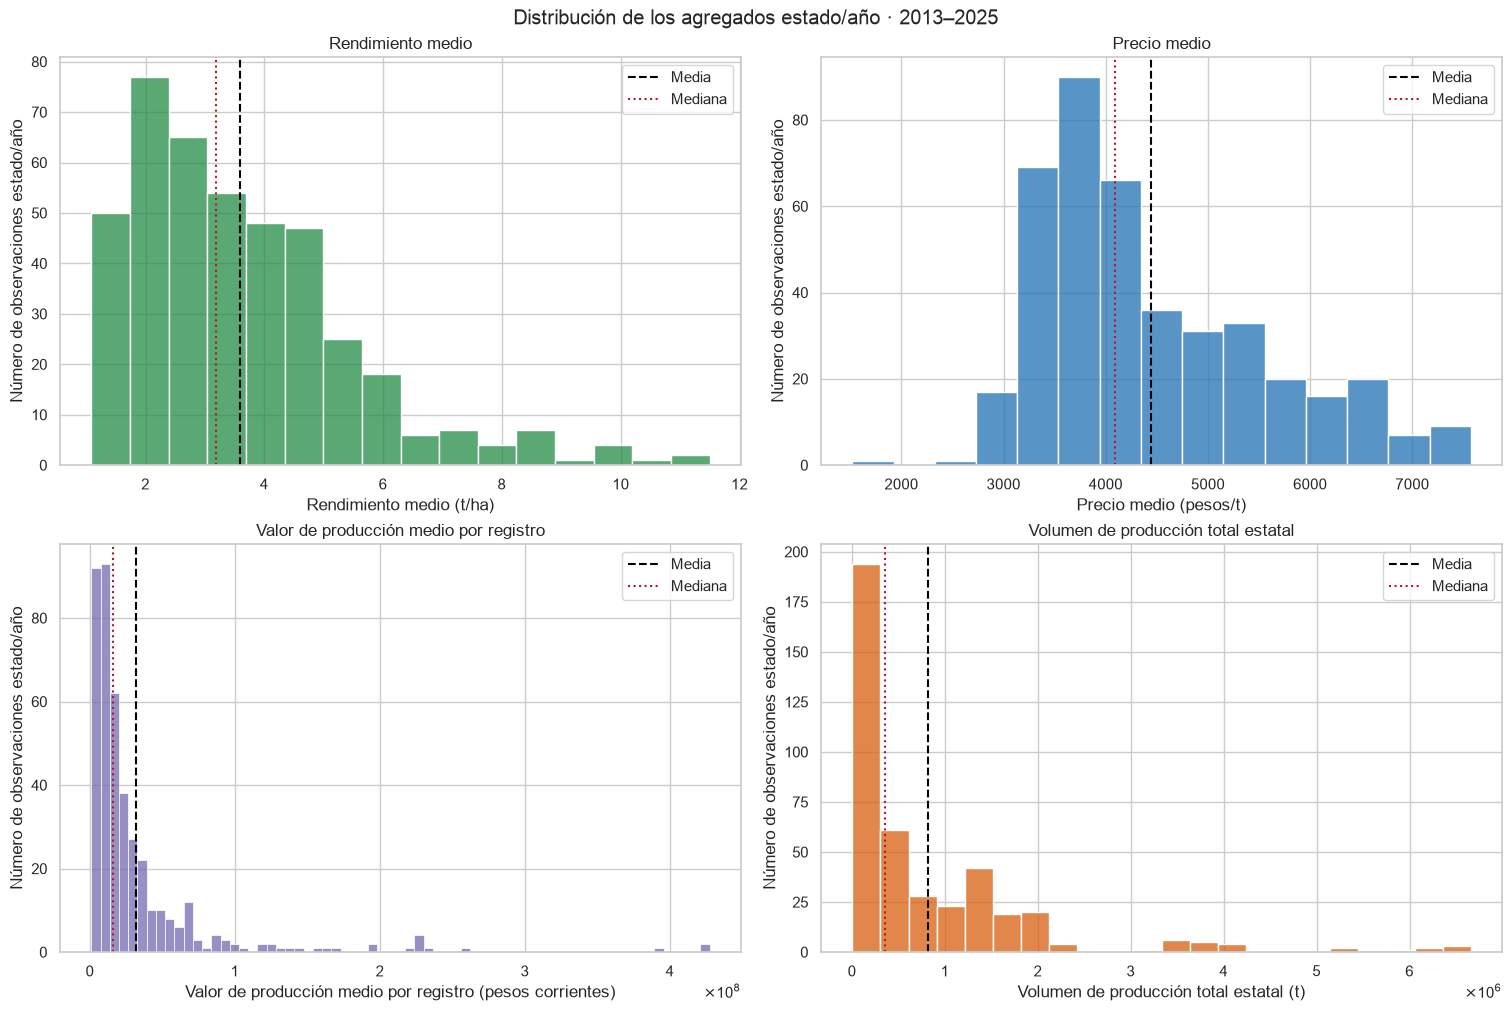

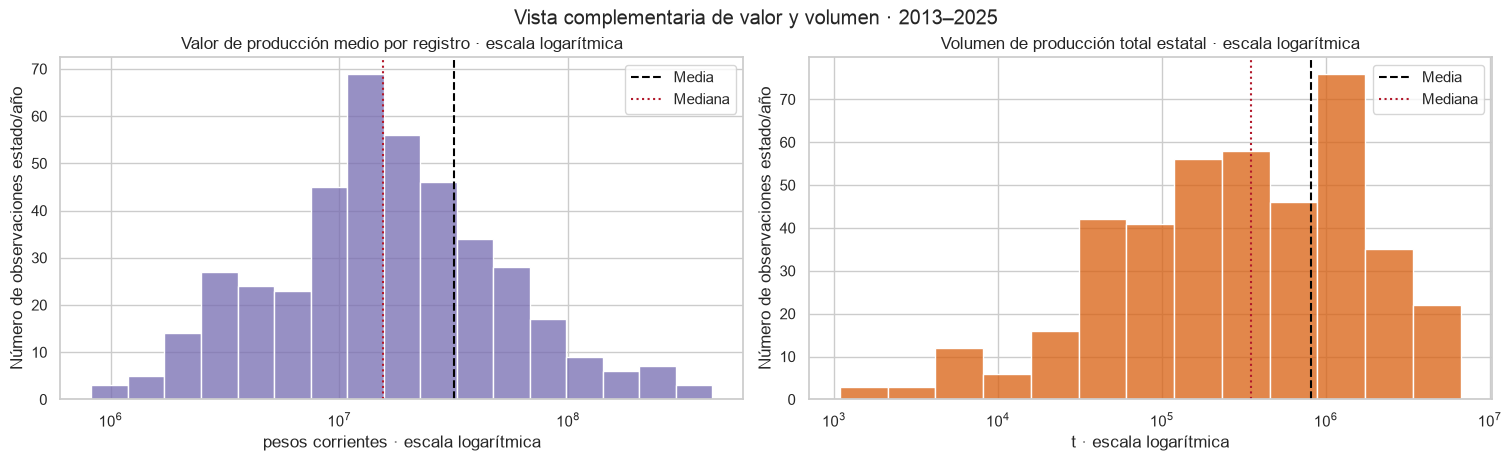

In [26]:
# Centralizamos nombres, unidades y colores para evitar etiquetas inconsistentes entre figuras.
especificaciones_univariables = {
    'Rendimiento': {'etiqueta': 'Rendimiento medio', 'unidad': 't/ha', 'color': '#238b45', 'paleta': 'Greens'},
    'Precio': {'etiqueta': 'Precio medio', 'unidad': 'pesos/t', 'color': '#2171b5', 'paleta': 'Blues'},
    'Valorproduccion': {'etiqueta': 'Valor de producción medio por registro', 'unidad': 'pesos corrientes', 'color': '#756bb1', 'paleta': 'Purples'},
    'Volumenproduccion': {'etiqueta': 'Volumen de producción total estatal', 'unidad': 't', 'color': '#d95f0e', 'paleta': 'Oranges'},
}
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ejes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
    for ax, (variable, tabla) in zip(ejes.flat, agregados_univariables.items()):
        especificacion = especificaciones_univariables[variable]
        sns.histplot(data=tabla, x=variable, bins='fd', color=especificacion['color'], ax=ax)
        ax.axvline(tabla[variable].mean(), color='black', linestyle='--', label='Media')
        ax.axvline(tabla[variable].median(), color='#b2182b', linestyle=':', label='Mediana')
        ax.set(title=especificacion['etiqueta'],
               xlabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})",
               ylabel='Número de observaciones estado/año')
        ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 6), useMathText=True)
        ax.legend()
    fig.suptitle(f'Distribución de los agregados estado/año · {periodo_univariable}')
    plt.show()

    # La vista complementaria usa intervalos logarítmicos solo si no oculta ceros.
    fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
    for ax, variable in zip(ejes, ['Valorproduccion', 'Volumenproduccion']):
        tabla = agregados_univariables[variable]
        especificacion = especificaciones_univariables[variable]
        usar_log = bool(tabla[variable].gt(0).all())
        sns.histplot(data=tabla, x=variable, bins='fd', log_scale=usar_log,
                     color=especificacion['color'], ax=ax)
        ax.axvline(tabla[variable].mean(), color='black', linestyle='--', label='Media')
        ax.axvline(tabla[variable].median(), color='#b2182b', linestyle=':', label='Mediana')
        escala = 'logarítmica' if usar_log else 'lineal (incluye ceros)'
        ax.set(title=f"{especificacion['etiqueta']} · escala {escala}",
               xlabel=f"{especificacion['unidad']} · escala {escala}",
               ylabel='Número de observaciones estado/año')
        ax.legend()
    fig.suptitle(f'Vista complementaria de valor y volumen · {periodo_univariable}')
    plt.show()

#### 3.6 Boxplots: variación anual dentro de cada estado

Cada caja resume los **agregados anuales de un estado**: no representa la dispersión municipal. Ordenamos los estados por su mediana; dentro de cada figura, un tono más oscuro representa una mediana mayor. La intensidad no debe compararse entre variables con unidades diferentes.

La caja abarca Q1–Q3 y la línea interior indica la mediana. Los bigotes alcanzan los valores observados dentro de 1.5 RIC; los puntos exteriores se conservan y no se consideran automáticamente errores. Los cuartiles y bigotes se calculan en las unidades originales. En volumen y valor aplicamos después una escala logarítmica al eje para leer diferencias de magnitud; si hubiera ceros, se usaría una escala simétrica logarítmica con tramo lineal entre −1 y 1, conservándolos.

La variación entre años puede reflejar tendencias y cambios de composición, no solo variabilidad aleatoria.

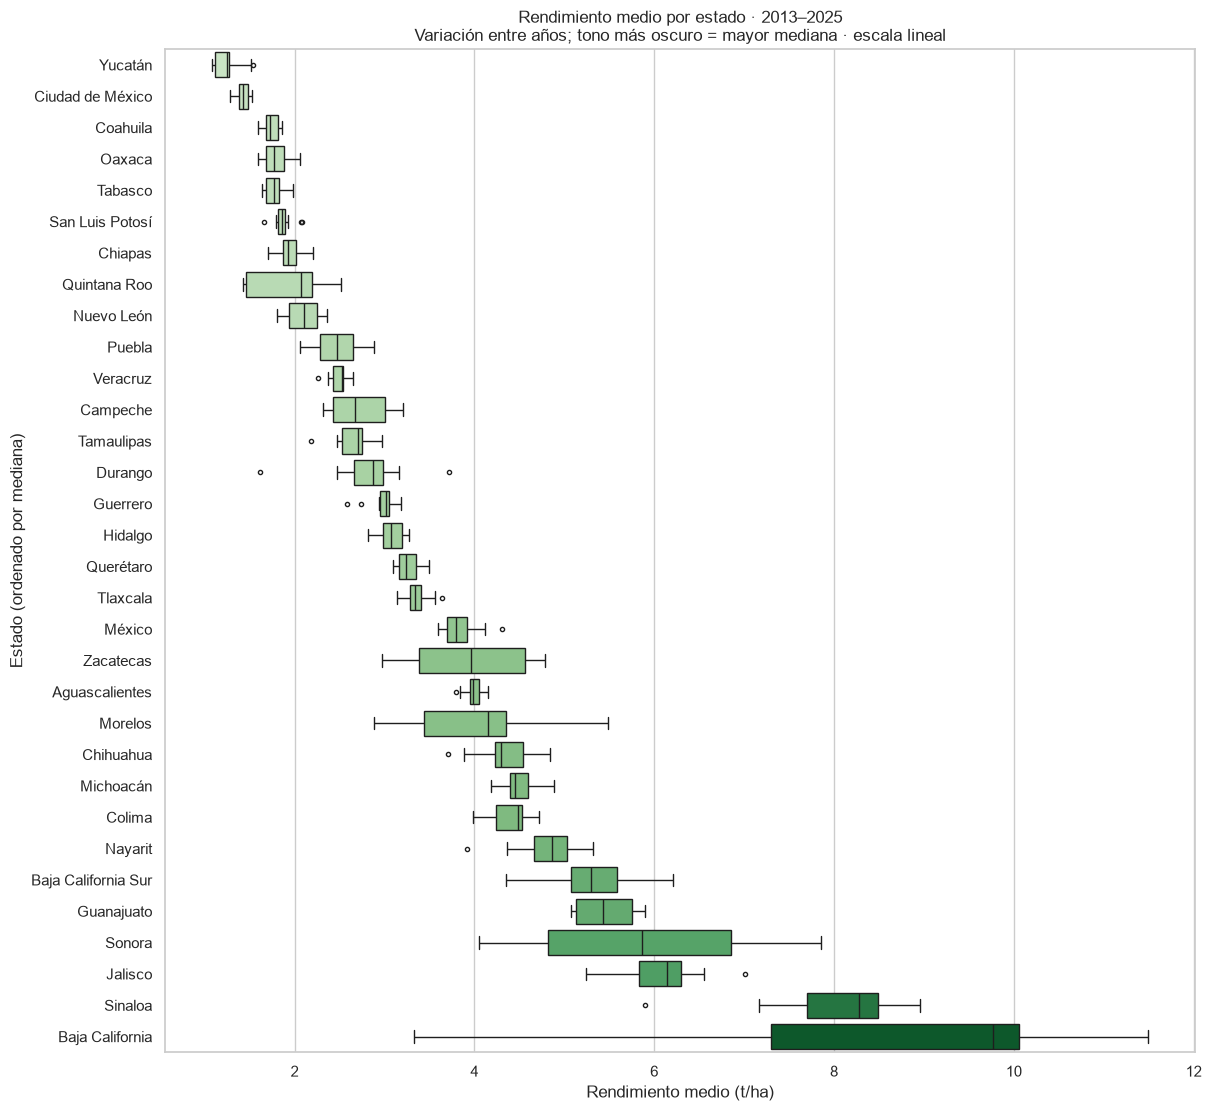

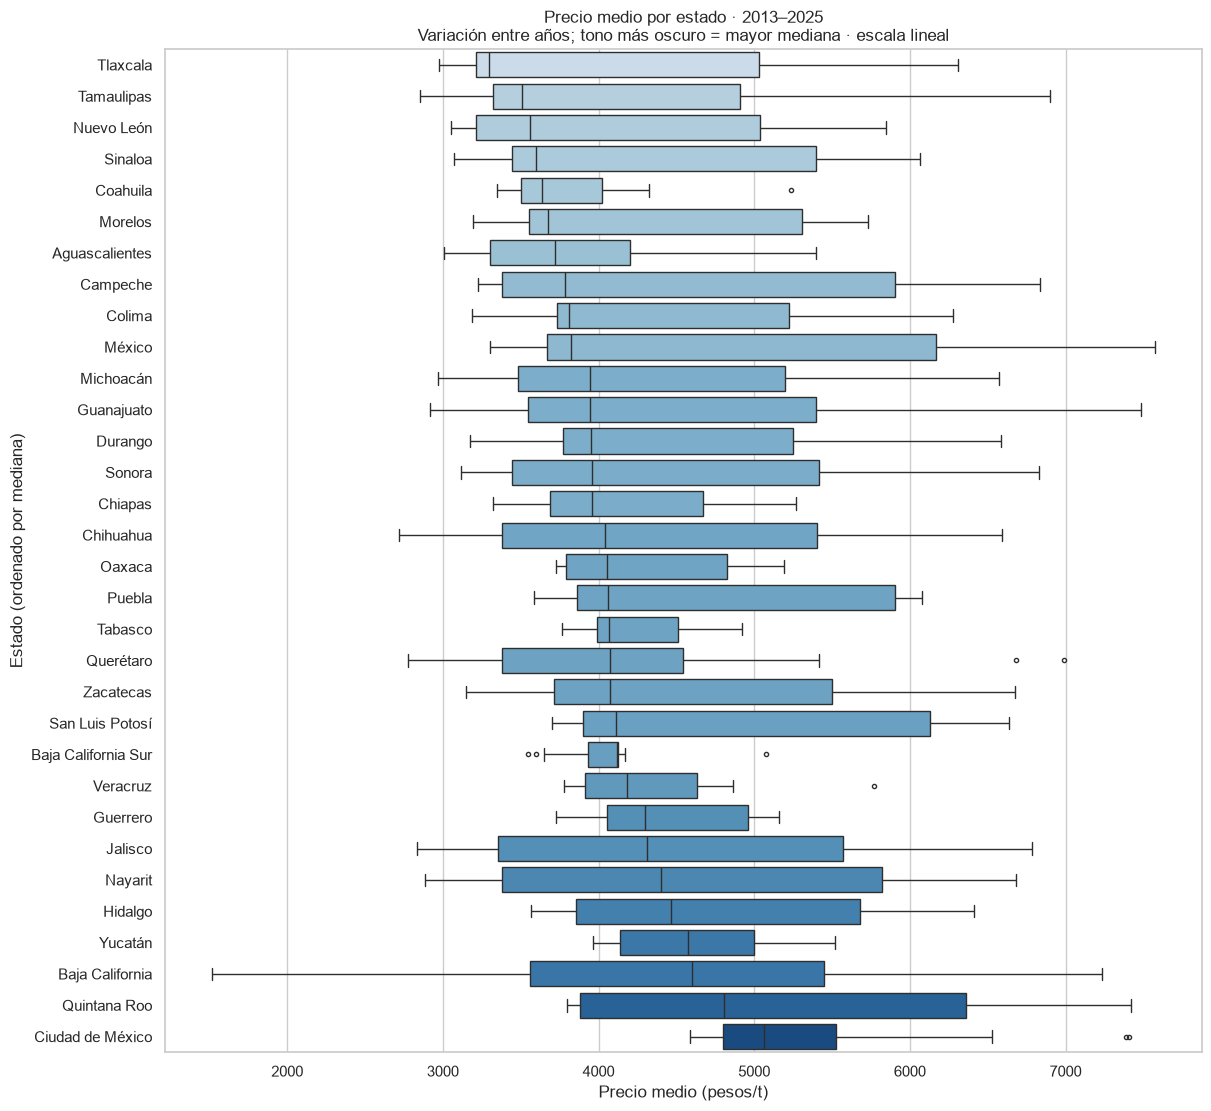

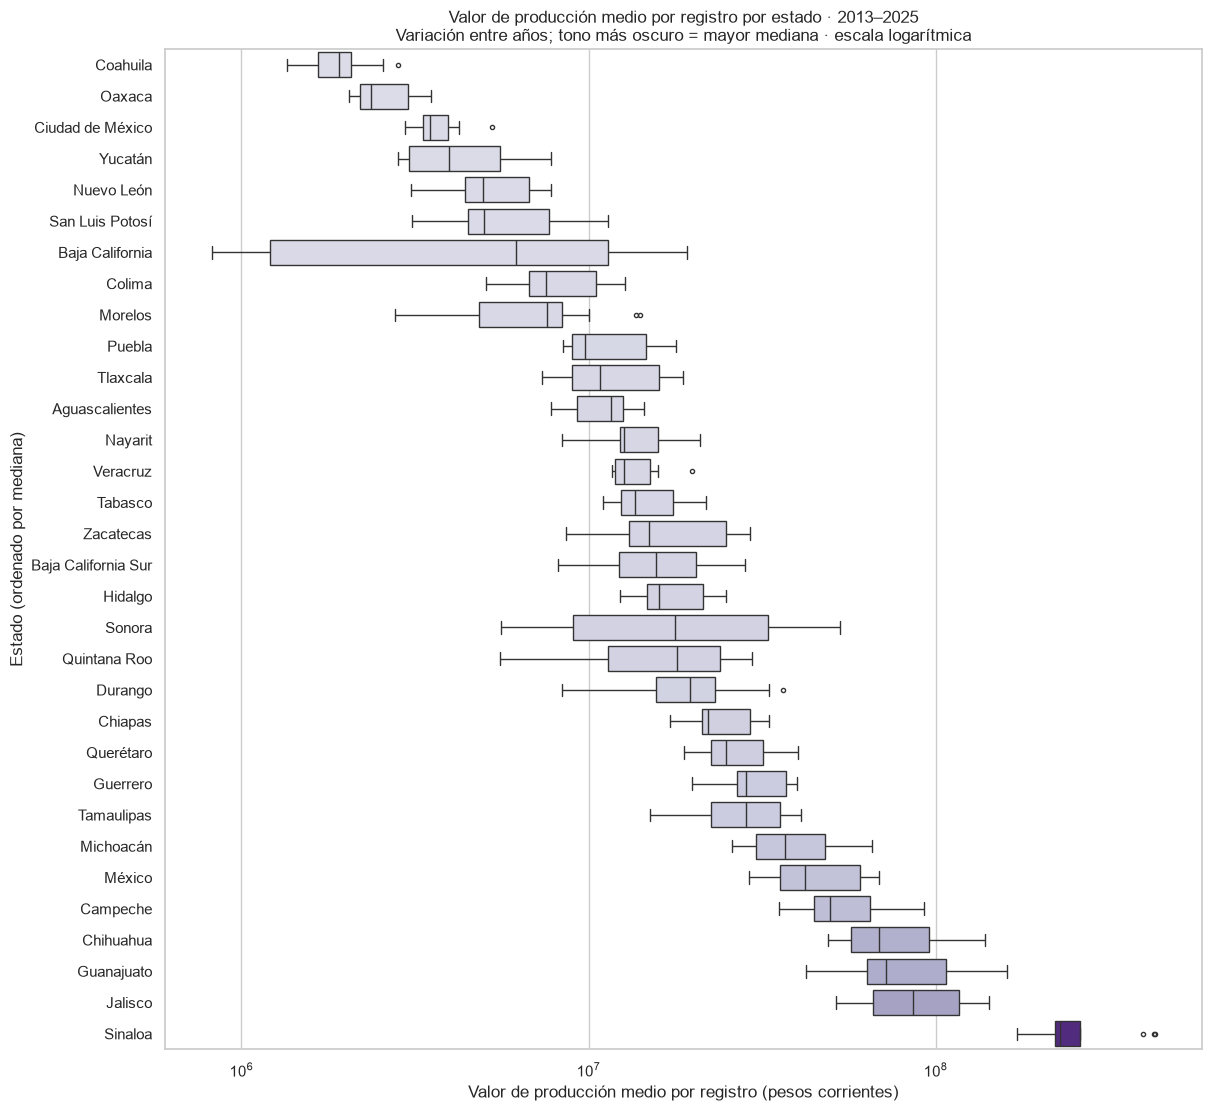

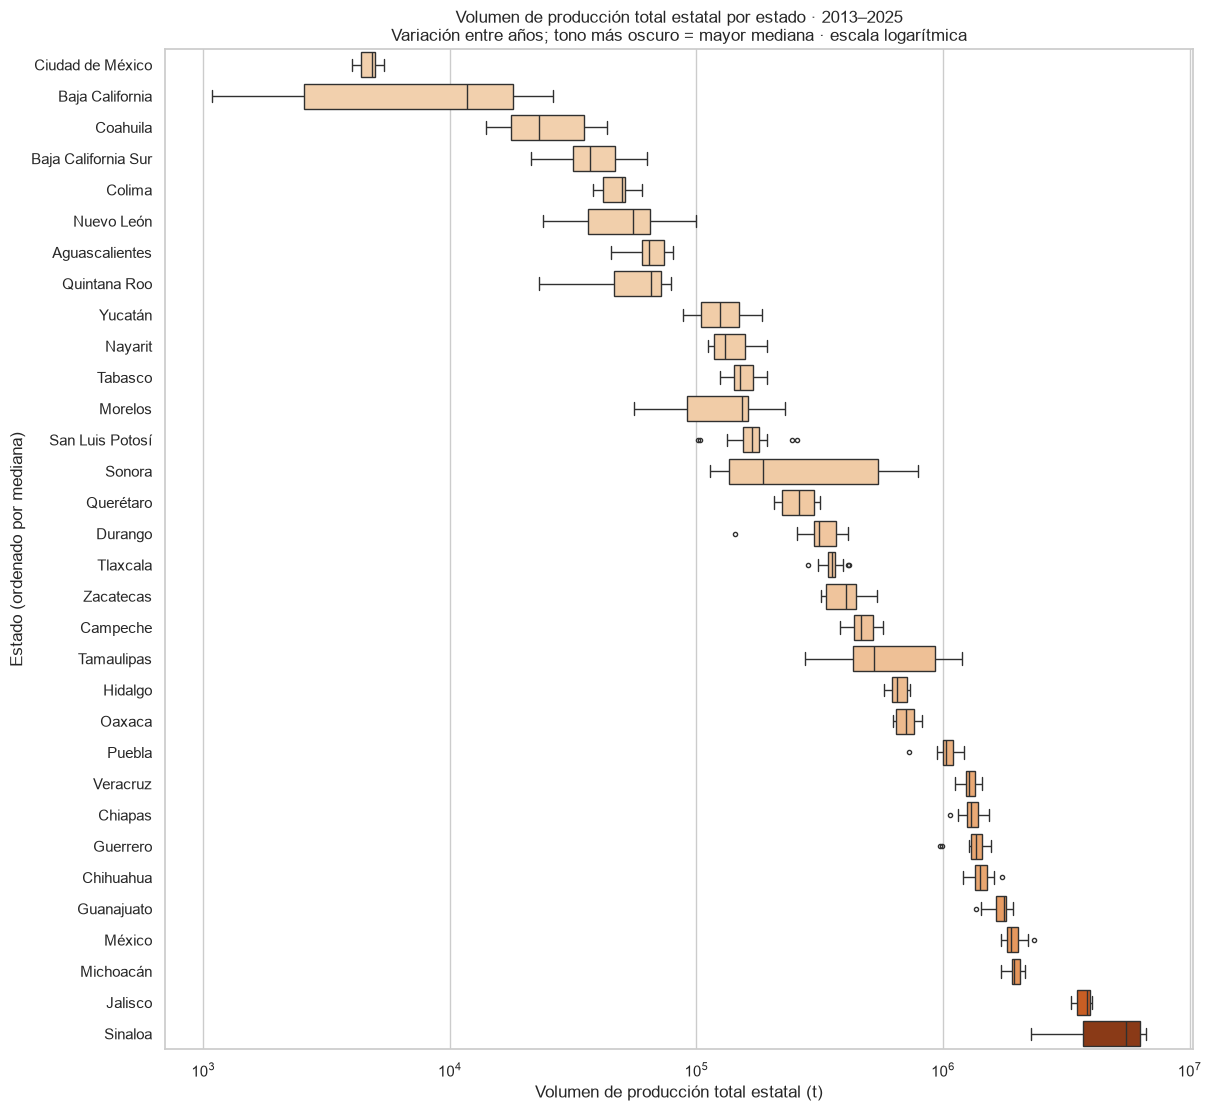

In [27]:
# Aplicamos la escala después del cálculo estadístico para conservar los cuartiles originales.
def escalar_magnitud_univariable(ax, valores, eje):
    escala = 'log' if valores.gt(0).all() else 'symlog'
    opciones = {} if escala == 'log' else {'linthresh': 1}
    if eje == 'x':
        ax.set_xscale(escala, **opciones)
    else:
        ax.set_yscale(escala, **opciones)
    return 'logarítmica' if escala == 'log' else 'simétrica logarítmica (tramo lineal ±1)'

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    for variable, tabla in agregados_univariables.items():
        especificacion = especificaciones_univariables[variable]
        medianas = tabla.groupby('Nomestado')[variable].median().sort_values()
        normalizar_mediana = Normalize(vmin=medianas.min(), vmax=medianas.max())
        mapa_color = sns.color_palette(especificacion['paleta'], as_cmap=True)
        # Evitamos el extremo blanco de la paleta y asignamos intensidad según la mediana.
        colores_mediana = {
            estado: mapa_color(0.25 + 0.65 * float(normalizar_mediana(mediana)))
            for estado, mediana in medianas.items()
        }
        fig, ax = plt.subplots(figsize=(12, 11), constrained_layout=True)
        sns.boxplot(data=tabla, x=variable, y='Nomestado', order=medianas.index,
                    hue='Nomestado', hue_order=medianas.index, palette=colores_mediana,
                    dodge=False, legend=False, whis=1.5, showfliers=True, fliersize=3, ax=ax)
        escala = 'lineal'
        if variable in ['Valorproduccion', 'Volumenproduccion']:
            escala = escalar_magnitud_univariable(ax, tabla[variable], 'x')
        ax.set(title=f"{especificacion['etiqueta']} por estado · {periodo_univariable}\n"
                     f'Variación entre años; tono más oscuro = mayor mediana · escala {escala}',
               xlabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})",
               ylabel='Estado (ordenado por mediana)')
        plt.show()

#### 3.7 Evolución temporal: un punto por estado y año

Las cuatro figuras utilizan directamente los dataframes creados en 3.2. Cada punto representa el agregado de un estado en un año. El eje horizontal conserva los años enteros y **cada estado mantiene el mismo color en todas las figuras**; aquí el color identifica una categoría y no una magnitud.

Mostramos todos los estados, con la leyenda fuera del área de datos. La superposición de puntos cercanos no implica falta de cobertura; la tabla de conteos permite verificarla. En volumen y valor se explicita la escala logarítmica (o simétrica logarítmica si hubiera ceros). Las diferencias verticales en escala logarítmica representan razones, no diferencias absolutas iguales.

Los precios y valores están expresados en **pesos corrientes**: sus variaciones no equivalen a cambios reales ajustados por inflación. Estos gráficos describen patrones, sin atribuir causalidad.

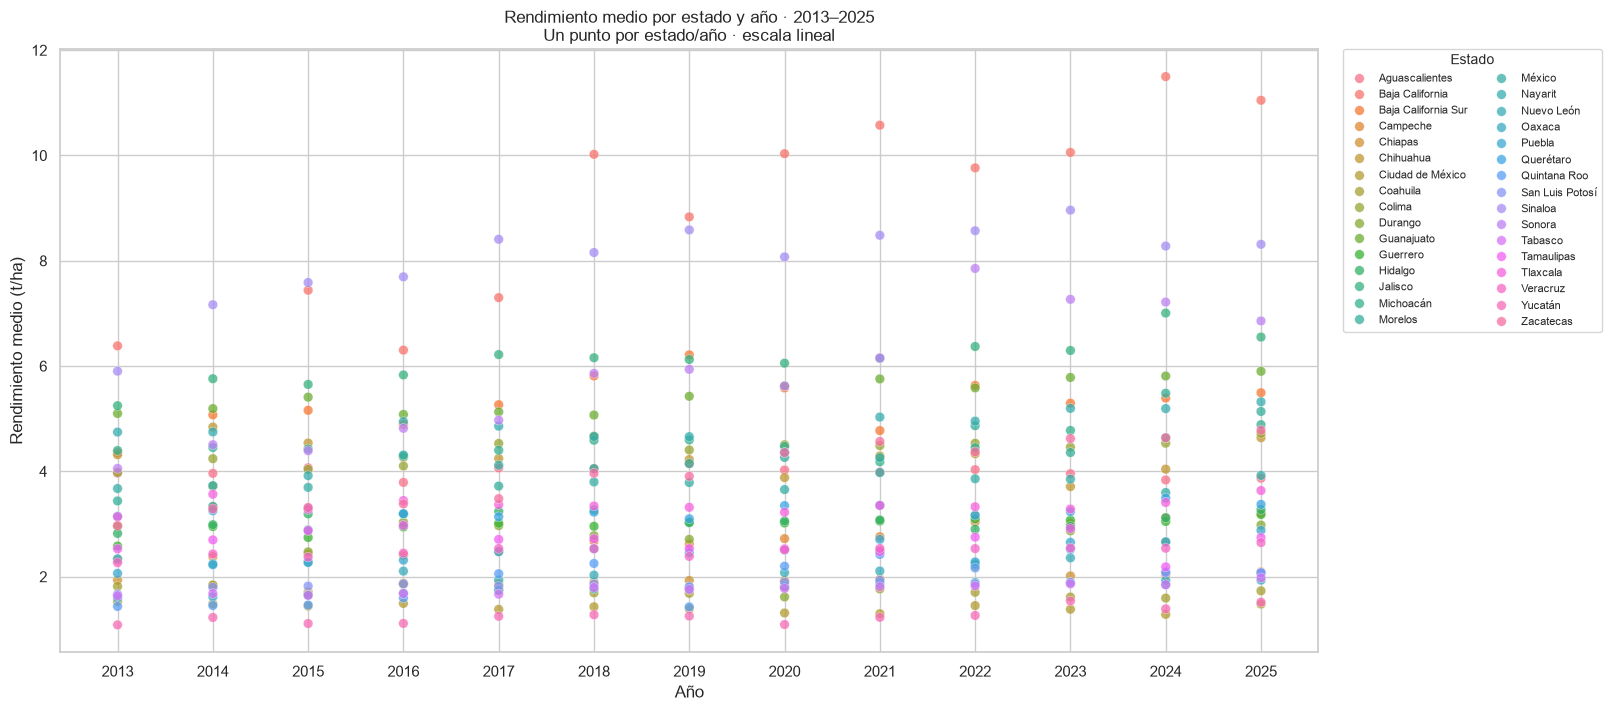

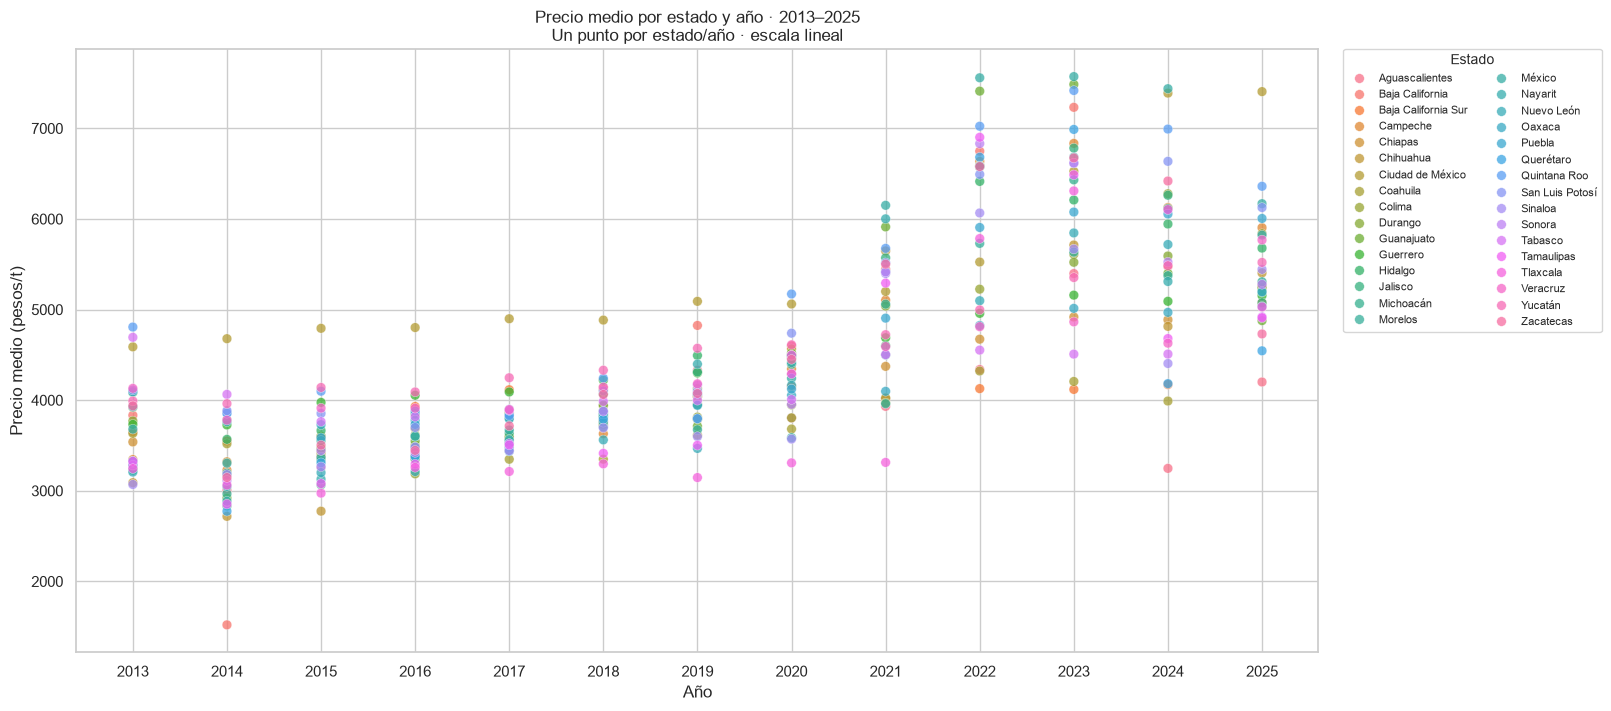

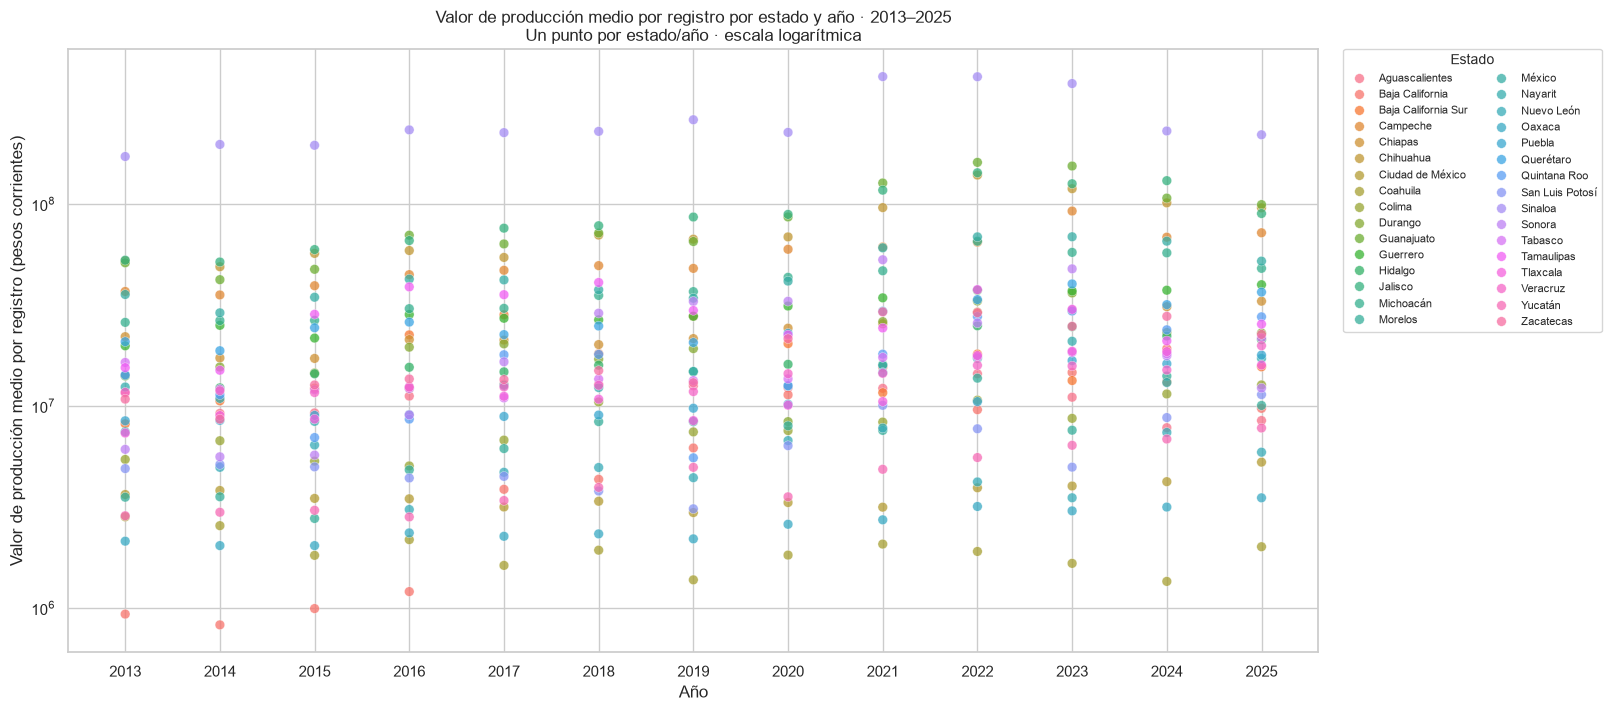

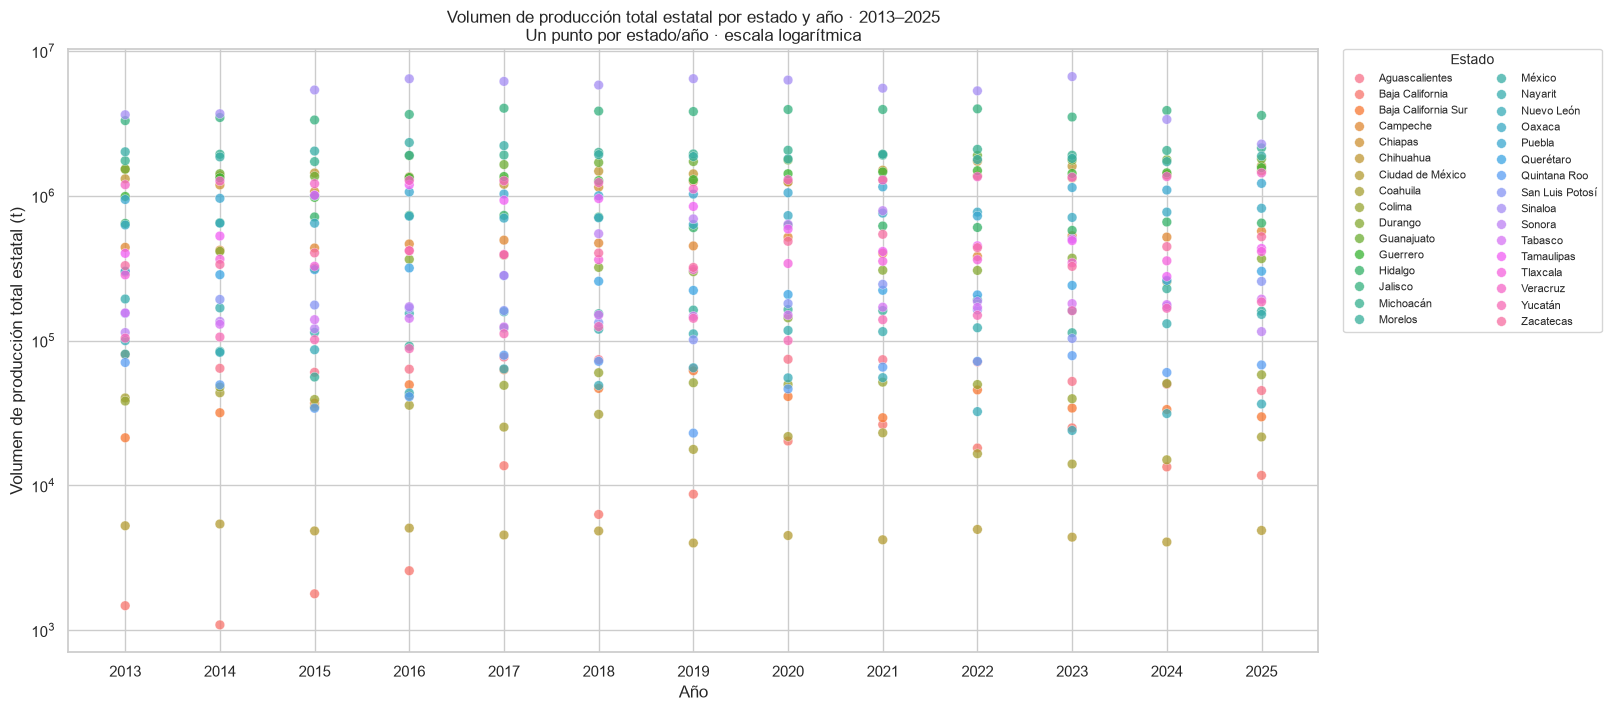

In [28]:
# Fijamos una paleta categórica única para identificar los estados en las cuatro figuras.
estados_univariables = sorted(maiz_univariable.Nomestado.unique())
paleta_estados_univariable = dict(zip(
    estados_univariables, sns.color_palette('husl', n_colors=len(estados_univariables))
))
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    for variable, tabla in agregados_univariables.items():
        especificacion = especificaciones_univariables[variable]
        fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
        sns.scatterplot(data=tabla, x='Anio', y=variable, hue='Nomestado',
                        hue_order=estados_univariables, palette=paleta_estados_univariable,
                        s=48, alpha=0.75, edgecolor='white', linewidth=0.3,
                        legend='full', ax=ax)
        escala = 'lineal'
        if variable in ['Valorproduccion', 'Volumenproduccion']:
            escala = escalar_magnitud_univariable(ax, tabla[variable], 'y')
        ax.set_xticks(anios_univariables)
        ax.set(title=f"{especificacion['etiqueta']} por estado y año · {periodo_univariable}\n"
                     f'Un punto por estado/año · escala {escala}',
               xlabel='Año', ylabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})")
        ax.legend(title='Estado', bbox_to_anchor=(1.02, 1), loc='upper left',
                  ncol=2, fontsize=8, title_fontsize=10, borderaxespad=0)
        plt.show()

#### 3.8 Lectura de los resultados y límites del análisis

El resumen siguiente se calcula a partir de las tablas, para que las conclusiones se actualicen al ejecutar el notebook. Describe la asimetría, el estado con mayor mediana anual en cada variable y la diferencia entre el primer y el último año usando **los mismos estados observados en ambos extremos**. Esta última comparación no resume todos los movimientos intermedios ni demuestra una tendencia monotónica. Para las tres variables promediadas, no equivale al crecimiento de un indicador nacional ponderado; para volumen, si se conservan los 32 estados, el cambio porcentual de su promedio coincide con el de la producción nacional total.

Las medias de rendimiento, precio y valor no son indicadores ponderados. El promedio entre estados da el mismo peso a cada estado, independientemente de su superficie, registros o producción. Incluso cuando dos distribuciones se superponen, pueden existir diferencias importantes entre municipios, ciclos y modalidades que esta agregación oculta. Las series anuales repetidas de un mismo estado tampoco deben tratarse como muestras independientes para inferencia estadística.

In [29]:
# Generamos una interpretación verificable sin fijar manualmente cifras o rankings.
conclusiones_univariables = []
for variable, tabla in agregados_univariables.items():
    especificacion = especificaciones_univariables[variable]
    serie = tabla[variable]
    medianas = tabla.groupby('Nomestado')[variable].median()
    estado_mayor_mediana = medianas.idxmax()
    extremos = tabla.pivot(index='Nomestado', columns='Anio', values=variable)
    extremos = extremos[[anios_univariables[0], anios_univariables[-1]]].dropna()
    media_inicial, media_final = extremos.mean().to_numpy()
    cambio = 100 * (media_final / media_inicial - 1) if media_inicial != 0 else np.nan
    direccion = 'positiva' if serie.skew() > 0 else 'negativa' if serie.skew() < 0 else 'nula'
    conclusiones_univariables.append(
        f"- **{especificacion['etiqueta']}:** media de los agregados = {serie.mean():,.2f}, "
        f"mediana = {serie.median():,.2f} {especificacion['unidad']}; "
        f'asimetría {direccion} ({serie.skew():.2f}). La mayor mediana anual corresponde a '
        f'**{estado_mayor_mediana}** ({medianas.max():,.2f}). '
        f'Entre {anios_univariables[0]} y {anios_univariables[-1]}, el promedio simple de '
        f'los agregados de los {len(extremos)} estados comunes cambia **{cambio:+.2f}%**.'
    )
porcentaje_ceros = 100 * sin_produccion.mean()
conclusiones_univariables.append(
    f'- **Ceros:** {sin_produccion.sum():,} registros ({porcentaje_ceros:.2f}%) no tienen '
    'producción. Permanecen en el análisis principal; la tabla de sensibilidad muestra '
    'cuánto cambian las medias de rendimiento y precio al condicionar a producción positiva.'
)
display(Markdown('\n\n'.join(conclusiones_univariables)))

- **Rendimiento medio:** media de los agregados = 3.59, mediana = 3.19 t/ha; asimetría positiva (1.34). La mayor mediana anual corresponde a **Baja California** (9.76). Entre 2013 y 2025, el promedio simple de los agregados de los 32 estados comunes cambia **+24.59%**.

- **Precio medio:** media de los agregados = 4,442.31, mediana = 4,091.80 pesos/t; asimetría positiva (0.84). La mayor mediana anual corresponde a **Ciudad de México** (5,061.44). Entre 2013 y 2025, el promedio simple de los agregados de los 32 estados comunes cambia **+47.11%**.

- **Valor de producción medio por registro:** media de los agregados = 31,667,816.55, mediana = 15,546,753.96 pesos corrientes; asimetría positiva (4.42). La mayor mediana anual corresponde a **Sinaloa** (228,889,485.44). Entre 2013 y 2025, el promedio simple de los agregados de los 32 estados comunes cambia **+63.84%**.

- **Volumen de producción total estatal:** media de los agregados = 814,464.46, mediana = 348,490.66 t; asimetría positiva (2.63). La mayor mediana anual corresponde a **Sinaloa** (5,535,561.11). Entre 2013 y 2025, el promedio simple de los agregados de los 32 estados comunes cambia **+7.74%**.

- **Ceros:** 292 registros (0.49%) no tienen producción. Permanecen en el análisis principal; la tabla de sensibilidad muestra cuánto cambian las medias de rendimiento y precio al condicionar a producción positiva.

#### 3.9 Comprobaciones de consistencia

Verificamos que los años observados coincidan exactamente con el intervalo inclusivo configurado, tanto en `maiz` como en cada agregado, sin admitir años posteriores a `DGSIAP_END_YEAR`. Verificamos que los cuatro dataframes tengan claves únicas, índices simples y la misma cobertura; contrastamos sus resultados con agregaciones directas y comprobamos que la suma de los volúmenes estatales anuales conserve la producción original. También verificamos la continuidad de Ciudad de México y la comparación condicionada a producción positiva. Estas comprobaciones validan las transformaciones añadidas, no sustituyen la validación de calidad de la fuente.

In [30]:
# Contrastamos las tablas accesibles con cálculos independientes sobre los registros.
operaciones_univariables = {
    'Rendimiento': 'mean', 'Precio': 'mean', 'Valorproduccion': 'mean', 'Volumenproduccion': 'sum'
}
assert anios_univariables == anios_esperados_dgsiap
assert maiz['Anio'].nunique() == DGSIAP_END_YEAR - DGSIAP_START_YEAR + 1
claves_esperadas = cobertura_estado_anio[claves_univariables]
for variable, tabla in agregados_univariables.items():
    assert sorted(tabla['Anio'].unique().tolist()) == anios_esperados_dgsiap
    assert not tabla.duplicated(claves_univariables).any()
    assert tabla.index.equals(pd.RangeIndex(len(tabla)))
    pd.testing.assert_frame_equal(tabla[claves_univariables], claves_esperadas)
    agrupacion_directa = maiz_univariable.groupby(claves_univariables)[variable]
    esperado = (agrupacion_directa.sum(min_count=1) if operaciones_univariables[variable] == 'sum'
                else agrupacion_directa.mean())
    pd.testing.assert_series_equal(tabla.set_index(claves_univariables)[variable], esperado)
np.testing.assert_allclose(volumenproduccion_estado_anio.Volumenproduccion.sum(),
                           maiz.Volumenproduccion.sum())
assert int(cobertura_estado_anio.SinProduccion.sum()) == int(maiz.Volumenproduccion.eq(0).sum())
assert cobertura_estado_anio.Registros.sum() == len(maiz)
assert 'Ciudad de México / DF' not in maiz_univariable.Nomestado.unique()
assert set(maiz_univariable.loc[maiz_univariable.Nomestado.eq('Ciudad de México'), 'Anio']) == set(
    maiz.loc[maiz.Idestado.eq(9), 'Anio']
)

# La comparación conserva todos los grupos y deja NaN cuando no hay producción positiva.
esperado_positivo = (maiz_univariable.loc[maiz_univariable.Volumenproduccion.gt(0)]
                     .groupby(claves_univariables)[['Rendimiento', 'Precio']].mean())
observado_positivo = comparacion_ceros_estado_anio.set_index(claves_univariables)[
    ['Rendimiento_positivo', 'Precio_positivo']
].rename(columns={'Rendimiento_positivo': 'Rendimiento', 'Precio_positivo': 'Precio'})
pd.testing.assert_frame_equal(observado_positivo, esperado_positivo.reindex(observado_positivo.index))
assert len(comparacion_ceros_estado_anio) == len(cobertura_estado_anio)
print('Comprobaciones correctas: agregados, cobertura, ceros y comparación condicionada.')

Comprobaciones correctas: agregados, cobertura, ceros y comparación condicionada.
